# **Deep Learning Project: Handwritten Digit Classifier (MNIST)**



# **📌 Objective:**



Build and evaluate a deep learning model that classifies handwritten digits (0–9) using the MNIST dataset. This project will reinforce core deep learning concepts such as data preprocessing, batch normalization, dropout regularization, and model evaluation through visual metrics

In [1]:
# Deep Learning Project: MNIST Handwritten Digit Classifier
# This notebook builds and evaluates a deep neural network for digit classification
# Key concepts: Batch Normalization, Dropout, Regularization, Model Evaluation

print("=" * 60)
print("MNIST Handwritten Digit Classifier")
print("=" * 60)

MNIST Handwritten Digit Classifier


# Import Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Load MNIST Dataset

In [3]:
# Load MNIST dataset
print("\nLoading MNIST dataset...")
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(f"Training set shape: {x_train.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Test set shape: {x_test.shape}")
print(f"Test labels shape: {y_test.shape}")


Loading MNIST dataset...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set shape: (60000, 28, 28)
Training labels shape: (60000,)
Test set shape: (10000, 28, 28)
Test labels shape: (10000,)


# Visualize Raw MNIST Data

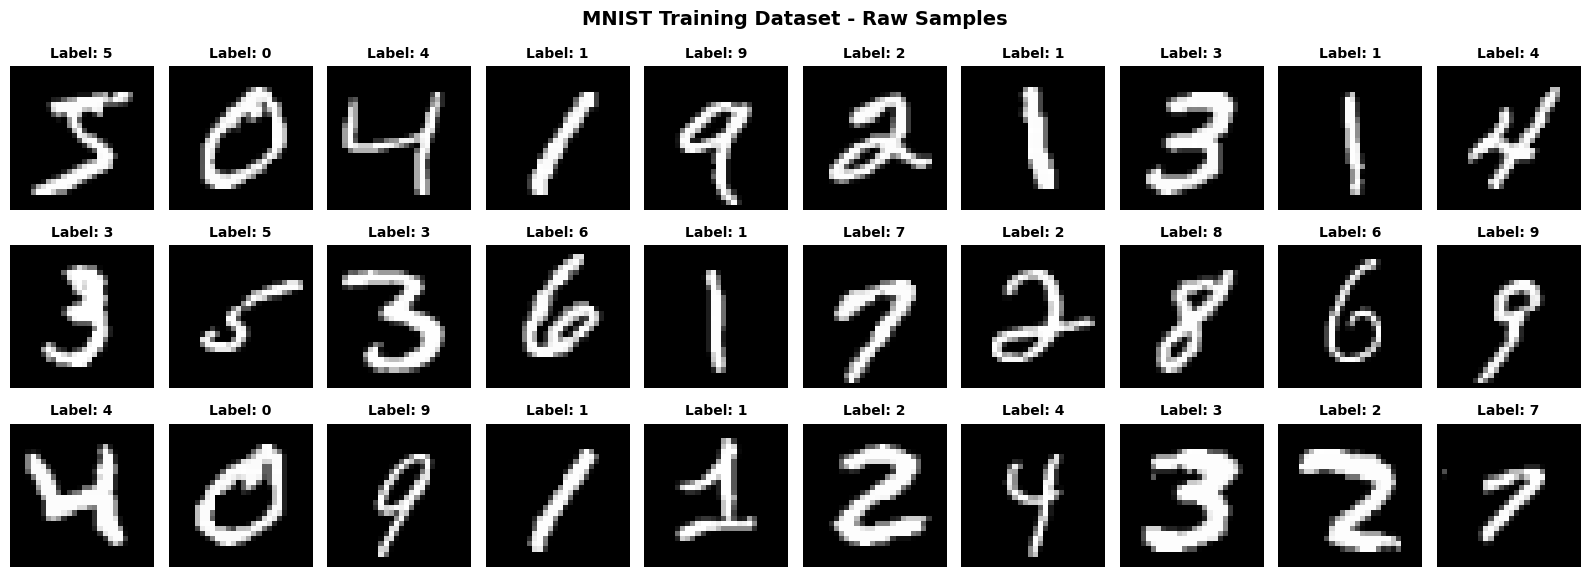

Image Data Type: uint8
Pixel Value Range: [0, 255]
Single Image Shape: (28, 28)


In [4]:
# Visualize some raw samples from the dataset
fig, axes = plt.subplots(3, 10, figsize=(16, 6))
axes = axes.ravel()

# Display first 30 training samples
for idx in range(30):
    ax = axes[idx]
    image = x_train[idx]  # Shape: (28, 28)
    label = y_train[idx]

    ax.imshow(image, cmap='gray')
    ax.set_title(f'Label: {label}', fontsize=10, fontweight='bold')
    ax.axis('off')

plt.suptitle('MNIST Training Dataset - Raw Samples', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Image Data Type: {x_train.dtype}")
print(f"Pixel Value Range: [{x_train.min()}, {x_train.max()}]")
print(f"Single Image Shape: {x_train[0].shape}")

# Explore Dataset Distribution

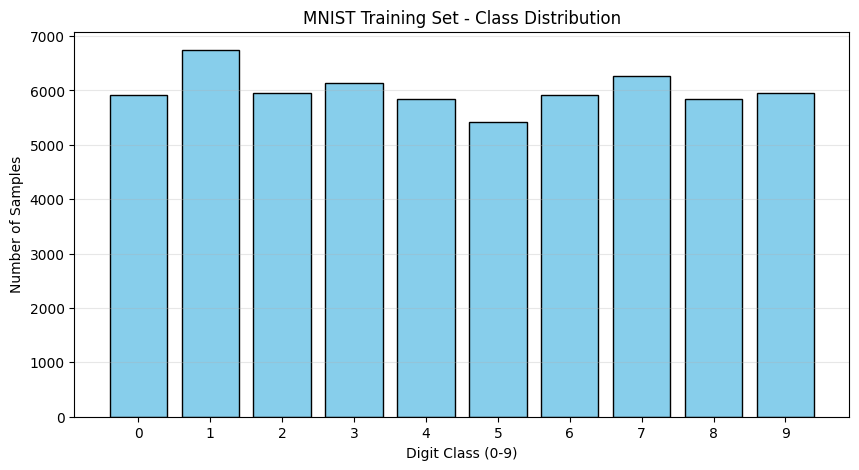


Class Distribution in Training Set:
  Digit 0: 5923 samples
  Digit 1: 6742 samples
  Digit 2: 5958 samples
  Digit 3: 6131 samples
  Digit 4: 5842 samples
  Digit 5: 5421 samples
  Digit 6: 5918 samples
  Digit 7: 6265 samples
  Digit 8: 5851 samples
  Digit 9: 5949 samples


In [5]:
# Check class distribution
unique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(unique, counts, color='skyblue', edgecolor='black')
plt.xlabel('Digit Class (0-9)')
plt.ylabel('Number of Samples')
plt.title('MNIST Training Set - Class Distribution')
plt.xticks(range(10))
plt.grid(True, alpha=0.3, axis='y')
plt.show()

print("\nClass Distribution in Training Set:")
for digit, count in zip(unique, counts):
    print(f"  Digit {digit}: {count} samples")

# Show Single Digit in Detail

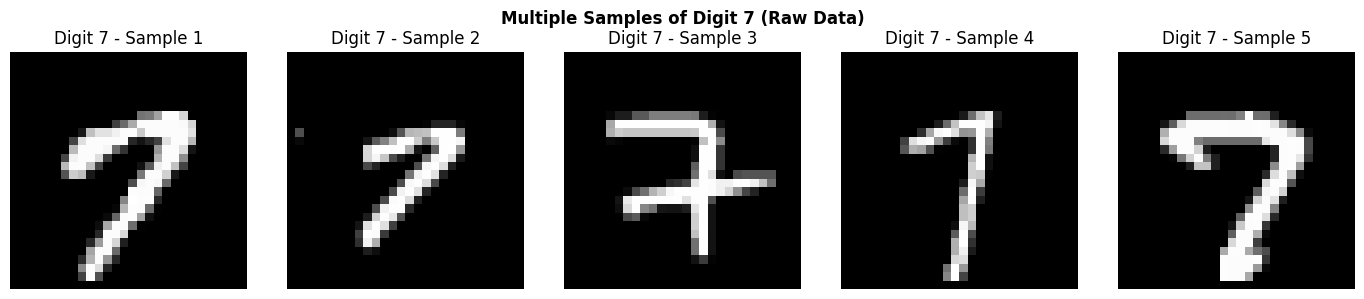


Pixel Statistics for one digit:
  Min pixel value: 0
  Max pixel value: 255
  Mean pixel value: 32.27


In [6]:
# Show a single digit in detail
fig, axes = plt.subplots(1, 5, figsize=(14, 3))

# Display 5 different samples of digit 7
digit_7_indices = np.where(y_train == 7)[0][:5]

for idx, ax in enumerate(axes):
    image = x_train[digit_7_indices[idx]]
    ax.imshow(image, cmap='gray')
    ax.set_title(f'Digit 7 - Sample {idx+1}')
    ax.axis('off')

plt.suptitle('Multiple Samples of Digit 7 (Raw Data)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Print pixel statistics
sample_image = x_train[digit_7_indices[0]]
print(f"\nPixel Statistics for one digit:")
print(f"  Min pixel value: {sample_image.min()}")
print(f"  Max pixel value: {sample_image.max()}")
print(f"  Mean pixel value: {sample_image.mean():.2f}")

# Preprocessing

In [7]:
# Normalize pixel values to [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print(f"Normalized training data range: [{x_train.min()}, {x_train.max()}]")

# Flatten 28x28 images to 784-dimensional vectors
x_train_flat = x_train.reshape(-1, 28 * 28)
x_test_flat = x_test.reshape(-1, 28 * 28)

print(f"Flattened training shape: {x_train_flat.shape}")

# One-hot encode labels
y_train_encoded = to_categorical(y_train, 10)
y_test_encoded = to_categorical(y_test, 10)

print(f"Encoded training labels shape: {y_train_encoded.shape}")

Normalized training data range: [0.0, 1.0]
Flattened training shape: (60000, 784)
Encoded training labels shape: (60000, 10)


# Build Model Architecture

In [8]:
# Build deep neural network
model = models.Sequential([
    # Input layer
    layers.Input(shape=(784,)),

    # Hidden Layer 1
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    # Hidden Layer 2
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    # Hidden Layer 3
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    # Output layer
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,554 (955.29 KB)

 Trainable params: 243,658 (951.79 KB)

 Non-trainable params: 896 (3.50 KB)

# Compile Model

In [9]:
# Compile the model
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


# Train Model

In [10]:
# Train the model
print("\nTraining model...")
history = model.fit(
    x_train_flat, y_train_encoded,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

print("\nTraining completed!")


Training model...
Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8610 - loss: 0.4591 - val_accuracy: 0.9517 - val_loss: 0.1572
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9376 - loss: 0.2081 - val_accuracy: 0.9638 - val_loss: 0.1226
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9523 - loss: 0.1605 - val_accuracy: 0.9661 - val_loss: 0.1116
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9586 - loss: 0.1368 - val_accuracy: 0.9702 - val_loss: 0.1030
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9655 - loss: 0.1148 - val_accuracy: 0.9715 - val_loss: 0.0944
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9688 - loss: 0.1032 - val_accuracy: 0.9734 - val_loss: 0.0874
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9705 - loss: 0.0931 - val_accuracy: 0.9749 - val_loss: 0.0873
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9726 - loss: 

# Plot Training History - Accuracy

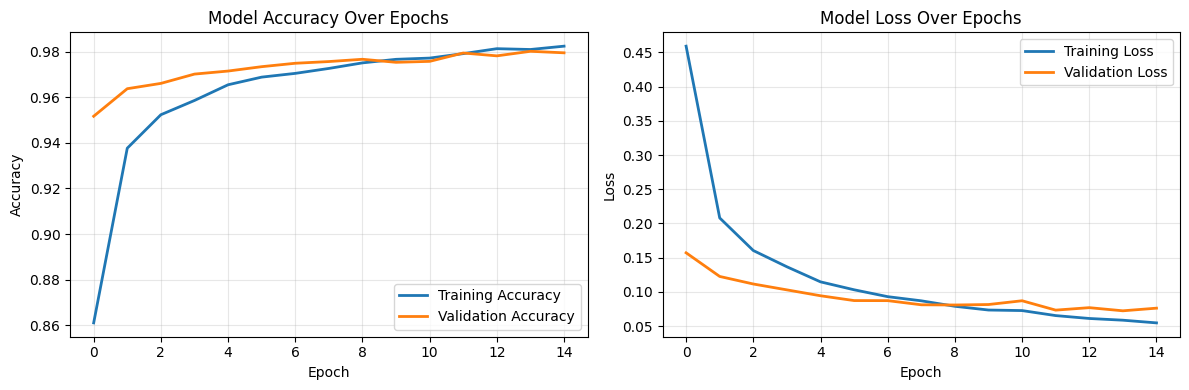

Training visualization complete!


In [11]:
# Plot training vs validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot training vs validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss Over Epochs')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Training visualization complete!")

# Evaluate on Test Set

In [12]:
# Evaluate model on test set
print("\nEvaluating on test set...")
test_loss, test_accuracy = model.evaluate(x_test_flat, y_test_encoded, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


Evaluating on test set...
Test Loss: 0.0660
Test Accuracy: 0.9807 (98.07%)


# Detailed Classification Report

In [13]:
# Generate predictions on test set
y_pred_prob = model.predict(x_test_flat, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)]))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.99      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.99      0.97      0.98       982
           5       0.99      0.97      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.98      0.98       974
           9       0.97      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



# Confusion Matrix

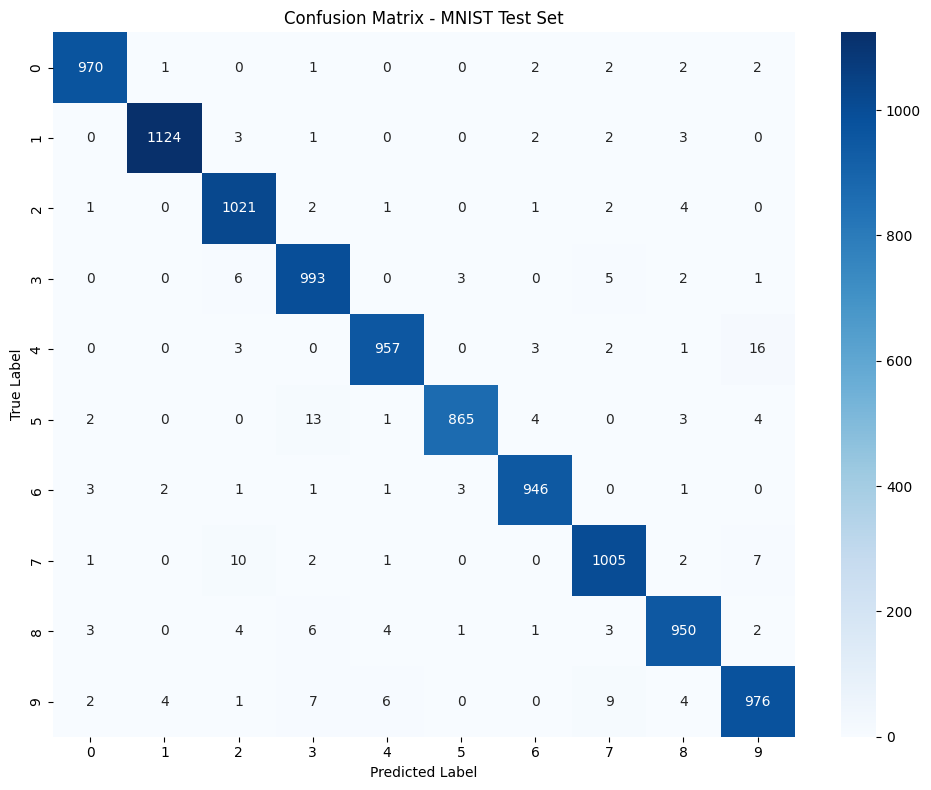

In [14]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - MNIST Test Set')
plt.tight_layout()
plt.show()

# Visualize Sample Predictions

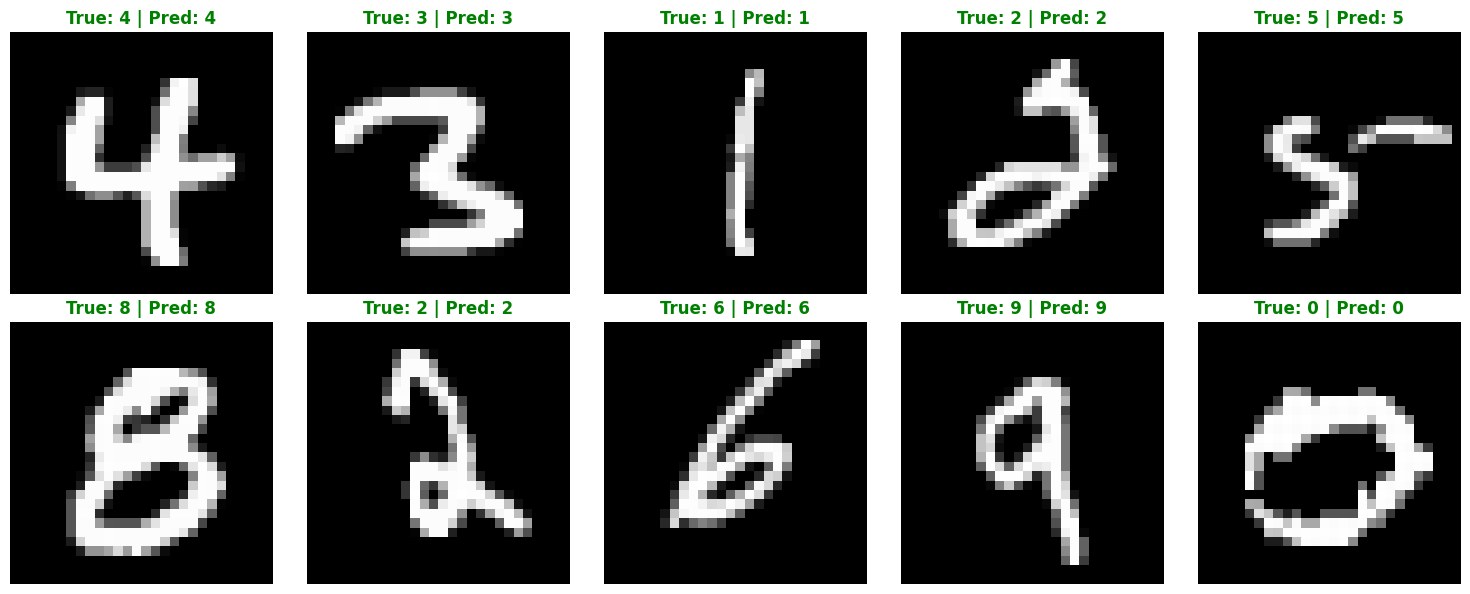

Visualization complete!


In [15]:
# Visualize sample predictions
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

# Select 10 random test samples
sample_indices = np.random.choice(len(x_test), 10, replace=False)

for idx, ax in enumerate(axes):
    sample_idx = sample_indices[idx]
    image = x_test[sample_idx]
    true_label = y_test[sample_idx]
    pred_label = y_pred[sample_idx]

    ax.imshow(image, cmap='gray')
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f'True: {true_label} | Pred: {pred_label}', color=color, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

print("Visualization complete!")

# Summary

In [16]:
print("\n" + "=" * 60)
print("PROJECT SUMMARY")
print("=" * 60)
print(f"✓ Model Architecture: 3 Hidden Layers (256 → 128 → 64)")
print(f"✓ Regularization: Batch Normalization + Dropout")
print(f"✓ Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"✓ Total Trainable Parameters: {model.count_params():,}")
print("=" * 60)


PROJECT SUMMARY
✓ Model Architecture: 3 Hidden Layers (256 → 128 → 64)
✓ Regularization: Batch Normalization + Dropout
✓ Final Test Accuracy: 98.07%
✓ Total Trainable Parameters: 244,554
